<a href="https://colab.research.google.com/github/Ksenia-Savich/cooperative/blob/main/preprocessing_virtual_assis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install pymorphy3 gensim beautifulsoup4 nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 41.7 MB/s  0:00:00


In [6]:
import numpy as np
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

#для моделей
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.manifold import TSNE

In [7]:
nltk.download("stopwords", quiet=True)
nltk.download('punkt', quiet=True)

True

In [14]:
# загрузка датасета, разделитель табуляция
df = pd.read_csv("virtual_assistant_dataset_russian.csv", encoding="utf-8")
print(df.columns.tolist())
print("\n")

# выводим первые 10 строк
print("=== ПЕРВЫЕ 10 СТРОК ===")
display(df.head(10))  # display() в Colab рисует красивую таблицу

['user_id', 'category', 'text', 'response_time', 'quality_rating', 'device', 'task_successful']


=== ПЕРВЫЕ 10 СТРОК ===


,user_id,category,text,response_time,quality_rating,device,task_successful
0,fc0304e8-55ab-42fd-84bb-e3df6b62f606,новости,Расскажи последние новости экономики,1.47,4,смарт-часы,True
1,d0c1993d-32e2-4a52-af6c-096a34b5305f,погода,Какая погода сегодня в Москве?,4.88,6,умная колонка,False
2,adc1ee79-b43c-441d-8ff2-838ec28ab41c,навигация,Как доехать до центра?,6.96,7,планшет,True
3,93472d1d-c987-4990-8827-d22ccf9ba92e,финансы,Проверь баланс карты,0.68,7,ноутбук,True
4,24a776f7-c3bb-4109-a1ef-fe8acec6e63c,покупки,Покажи акции на одежду,0.21,10,смартфон,True
5,92501487-c9e8-495d-8da1-cb235a97d7be,покупки,Покажи акции на одежду,6.30,6,умная колонка,False
6,04b44532-04ed-4293-a89e-0b5595f79bb1,навигация,Построй маршрут до ближайшей аптеки,1.48,7,планшет,False
7,34699609-8255-44ea-b0c7-f9e1da1c0242,погода,Прогноз погоды на завтра в Санкт-Петербурге,2.34,5,смартфон,True
8,721f4273-a606-4cd9-904c-e477941aaedf,покупки,Где купить ноутбук?,10.33,10,умная колонка,True
9,63ada0de-808a-45c5-9356-665b2fb482a9,навигация,Сколько времени до аэропорта?,0.21,8,смартфон,False


In [15]:
df['label'] = df['task_successful']
df = df.dropna(subset=['text'])
print(df.head())

                                user_id   category  \
0  fc0304e8-55ab-42fd-84bb-e3df6b62f606    новости   
1  d0c1993d-32e2-4a52-af6c-096a34b5305f     погода   
2  adc1ee79-b43c-441d-8ff2-838ec28ab41c  навигация   
3  93472d1d-c987-4990-8827-d22ccf9ba92e    финансы   
4  24a776f7-c3bb-4109-a1ef-fe8acec6e63c    покупки   

                                   text  response_time  quality_rating  \
0  Расскажи последние новости экономики           1.47               4   
1        Какая погода сегодня в Москве?           4.88               6   
2                Как доехать до центра?           6.96               7   
3                  Проверь баланс карты           0.68               7   
4                Покажи акции на одежду           0.21              10   

          device  task_successful  label  
0     смарт-часы             True   True  
1  умная колонка            False  False  
2        планшет             True   True  
3        ноутбук             True   True  
4       смартфо

In [16]:
print("Колонки в датасете:", df.columns.tolist())
display(df.head())

Колонки в датасете: ['user_id', 'category', 'text', 'response_time', 'quality_rating', 'device', 'task_successful', 'label']


,user_id,category,text,response_time,quality_rating,device,task_successful,label
0,fc0304e8-55ab-42fd-84bb-e3df6b62f606,новости,Расскажи последние новости экономики,1.47,4,смарт-часы,True,True
1,d0c1993d-32e2-4a52-af6c-096a34b5305f,погода,Какая погода сегодня в Москве?,4.88,6,умная колонка,False,False
2,adc1ee79-b43c-441d-8ff2-838ec28ab41c,навигация,Как доехать до центра?,6.96,7,планшет,True,True
3,93472d1d-c987-4990-8827-d22ccf9ba92e,финансы,Проверь баланс карты,0.68,7,ноутбук,True,True
4,24a776f7-c3bb-4109-a1ef-fe8acec6e63c,покупки,Покажи акции на одежду,0.21,10,смартфон,True,True


In [17]:
# стоп слова из nltk для русского языка
STOPWORDS = set(stopwords.words("russian"))

In [18]:
# ==== БАЗОВАЯ ОТЧИСТКА

# приведение к нижнему регистру — уменьшает размер словаря
df["text_ready"] = df["text"].str.lower()

def remove_html(text):
    """удаляет HTML-теги"""
    return re.sub(r"<[^>]+>", "", text)
df["text_ready"] = df["text_ready"].apply(remove_html)

def remove_urls(text):
    """удаляет ссылки http(s)://... и www..."""
    return re.sub(r"https?://\S+|www\.\S+", "", text)
df["text_ready"] = df["text_ready"].apply(remove_urls)

def remove_emoji(text):
    """удаляет эмодзи по диапазонам unicode кодов"""
    emoji_pattern = re.compile(
        "["
        u"\U0001F600-\U0001F64F"  # эмотиконы
        u"\U0001F300-\U0001F5FF"  # символы и пиктограммы
        u"\U0001F680-\U0001F6FF"  # транспорт
        u"\U0001F1E0-\U0001F1FF"  # флаги
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r"", text)
df["text_ready"] = df["text_ready"].apply(remove_emoji)

# удаление цифр через регулярное выражение \d+
df["text_ready"] = df["text_ready"].str.replace(r"\d+", "", regex=True)

# удаление пунктуации: всё, что не буква/цифра/пробел
df["text_ready"] = df["text_ready"].str.replace(r"[^\w\s]", "", regex=True)

def remove_stopwords(text):
    """убирает служебные слова"""
    return " ".join(word for word in str(text).split() if word not in STOPWORDS)
df["text_ready"] = df["text_ready"].apply(remove_stopwords)

In [19]:
# ==== ТОКЕНИЗАЦИЯ И ЛЕММАТИЗАЦИЯ

morph = MorphAnalyzer()

def tokenize_lemmas(sent, pat=r"(?u)\b\w\w+\b"):
    """
    Разбивает строку на токены
    и приводит каждый к лемме.
    """
    tokens = regexp_tokenize(sent, pat)   # \w\w+ = минимум 2 символа
    return [morph.parse(tok)[0].normal_form for tok in tokens]

df["tokens"] = df["text_ready"].apply(tokenize_lemmas)
# для моделей, ожидающих строку
df["text_lemmas"] = df["tokens"].apply(" ".join)

print(df[["text", "label", "text_lemmas"]].head())

                                   text  label  \
0  Расскажи последние новости экономики   True   
1        Какая погода сегодня в Москве?  False   
2                Как доехать до центра?   True   
3                  Проверь баланс карты   True   
4                Покажи акции на одежду   True   

                              text_lemmas  
0  рассказать последний новость экономика  
1                   погода сегодня москва  
2                           доехать центр  
3                  проверить баланс карта  
4                   показать акция одежда  


[('переведи', 4821), ('рублей', 4821), ('маме', 4821), ('нового', 4813), ('мире', 4813), ('найди', 4808), ('дешевые', 4808), ('наушники', 4808), ('денег', 4795), ('счете', 4795), ('проиграй', 4786), ('последний', 4786), ('альбом', 4786), ('imagine', 4786), ('dragons', 4786), ('включи', 4783), ('музыку', 4783), ('басты', 4783), ('прогноз', 4772), ('погоды', 4772)]
ТОП-20 в УСПЕШНЫХ отзывах:
[('последний', 7342), ('новость', 7276), ('погода', 7134), ('сколько', 7077), ('ноутбук', 7003), ('рассказать', 3702), ('экономика', 3702), ('новый', 3665), ('мир', 3665), ('доехать', 3652), ('центр', 3652), ('проиграть', 3640), ('альбом', 3640), ('imagine', 3640), ('dragons', 3640), ('перезагрузить', 3635), ('роутер', 3635), ('перевести', 3633), ('рубль', 3633), ('мама', 3633)]

ТОП-20 в НЕУСПЕШНЫХ отзывах:
[('ноутбук', 2419), ('сколько', 2413), ('погода', 2402), ('последний', 2357), ('новость', 2348), ('найти', 1263), ('дешёвый', 1263), ('наушник', 1263), ('купить', 1249), ('построить', 1234), ('ма

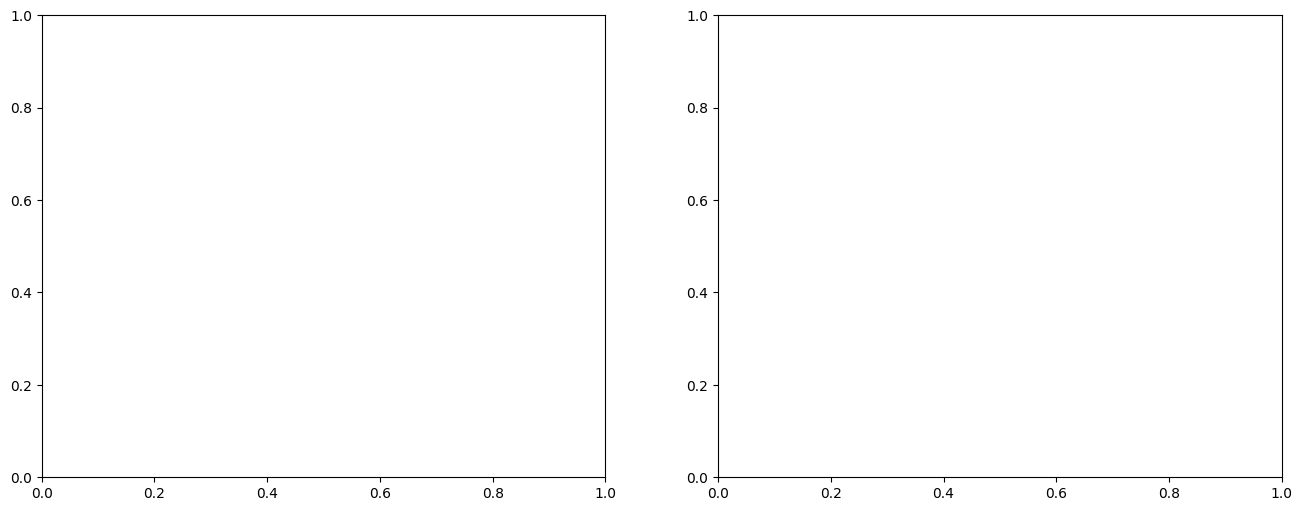

In [21]:
# ==== ЧАСТОТНЫЙ АНАЛИЗ ПО КЛАССАМ

# cчитаем частоты всех слов корпуса
cnt = Counter()
for text in df["text_ready"]:
    for word in text.split():
        cnt[word] += 1

print(cnt.most_common(20)) # для отчёта топ 20 самых частых

#удаляем 10 самых частых слов
freq_high = {w for w, _ in cnt.most_common(10)}
df["text_ready"] = df["text_ready"].apply(
    lambda t: " ".join(w for w in t.split() if w not in freq_high)
)
df["text_lemmas"] = df["tokens"].apply(" ".join)

# разделяем корпус по меткам
pos_tokens = [w for toks in df.loc[df["label"] == True, "tokens"] for w in toks]
neg_tokens = [w for toks in df.loc[df["label"] == False, "tokens"] for w in toks]

freq_pos = FreqDist(pos_tokens)
freq_neg = FreqDist(neg_tokens)

print("ТОП-20 в УСПЕШНЫХ отзывах:")
print(freq_pos.most_common(20))
print("\nТОП-20 в НЕУСПЕШНЫХ отзывах:")
print(freq_neg.most_common(20))

# визуализация — 20 самых частых слов для каждого класса
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

In [22]:
# ==== ГРАФИК ДЛЯ УСПЕШНЫХ
pos_words, pos_counts = zip(*freq_pos.most_common(20))
axes[0].bar(pos_words, pos_counts, color = 'green')
axes[0].set_title("успешные запросы")
axes[0].tick_params(axis='x', rotation=90) # чтобы подписи на наезжали
# ==== ГРАФИК ДЛЯ НЕУСПЕШНЫХ
neg_words, neg_counts = zip(*freq_neg.most_common(20))
axes[1].bar(neg_words, neg_counts, color='red')
axes[1].set_title("неуспешные запросы")
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.savefig("freq_plots.png", dpi=150)
print("Графики сохранены в файл freq_plots.png")

Графики сохранены в файл freq_plots.png


<Figure size 640x480 with 0 Axes>

In [25]:
import nltk
nltk.download('punkt_tab')

from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [26]:
# ======= word2vec ===========

# Обертка для подачи текста в Gensim
class MySentences(object):
    def __init__(self, docs):
        self.corpus = docs
    def __iter__(self):
        for doc in self.corpus:
            doc_sentences = sent_tokenize(doc)
            for sent in doc_sentences:
                yield simple_preprocess(sent)

# Берем уже лемматизированный текст для обучения
sentences = MySentences(df['text_lemmas'].tolist())

# Инициализация и обучение модели
w2v_model = Word2Vec(
    min_count=10,
    window=4,
    vector_size=300,
    negative=10,
    alpha=0.03,
    min_alpha=0.0007,
    sample=6e-5,
    sg=1 # Используем Skip-gram
)

w2v_model.build_vocab(sentences)
print("Обучение Word2Vec...")
w2v_model.train(sentences, total_examples=w2v_model.corpus_count, epochs=6, report_delay=1)
w2v_model.init_sims(replace=True) # Оптимизация памяти

Обучение Word2Vec...


/tmp/ipykernel_865/2505905985.py:31: DeprecationWarning: Call to deprecated `init_sims` (Gensim 4.0.0 implemented internal optimizations that make calls to init_sims() unnecessary. init_sims() is now obsoleted and will be completely removed in future versions. See https://github.com/RaRe-Technologies/gensim/wiki/Migrating-from-Gensim-3.x-to-4).
  w2v_model.init_sims(replace=True) # Оптимизация памяти


In [29]:
print(w2v_model.wv.most_similar(positive=["погода"], topn=10))
print(w2v_model.wv.most_similar(positive=["погода", "москва"], topn=10))
#print(w2v_model.wv.most_similar_to_given("хороший", ["товар", "продавец", "человек", "куртка"]))

[('санктпетербург', 0.9980282783508301), ('прогноз', 0.9974817037582397), ('завтра', 0.996931791305542), ('москва', 0.9901413321495056), ('сегодня', 0.9881045818328857), ('новый', 0.9679805040359497), ('выходной', 0.9679490327835083), ('роутер', 0.9673468470573425), ('перезагрузить', 0.9661044478416443), ('доехать', 0.9660539031028748)]
[('санктпетербург', 0.9963713884353638), ('завтра', 0.9953761696815491), ('прогноз', 0.9952763915061951), ('сегодня', 0.9950557351112366), ('новый', 0.9808815121650696), ('выходной', 0.9807026982307434), ('роутер', 0.9802761077880859), ('доехать', 0.9793951511383057), ('перезагрузить', 0.9793689846992493), ('мир', 0.9792250394821167)]


In [30]:
# ========== Bag of Words ============
bow_vectorizer = CountVectorizer()
bow_model = bow_vectorizer.fit_transform(df['text_lemmas'])
print(f"\nРазмерность матрицы Bag of Words: {bow_model.shape}")

# ========== TF-IDF ==================
tfidf_vectorizer = TfidfVectorizer()
tfidf_model = tfidf_vectorizer.fit_transform(df['text_lemmas'])
print(f"Размерность матрицы TF-IDF: {tfidf_model.shape}")


Размерность матрицы Bag of Words: (100000, 58)
Размерность матрицы TF-IDF: (100000, 58)


In [31]:
df.to_csv("processed_dataset.csv", index=False, encoding="utf-8-sig")